
Processing Mercado_Abastecedor_-_Antas_1.0.csv
Custom weekday+hour -> MAE: 234.75, RMSE: 381.96, SMAPE: 0.11
Custom hour -> MAE: 428.91, RMSE: 631.65, SMAPE: 0.21
Custom month+weekday+hour -> MAE: 235.52, RMSE: 384.51, SMAPE: 0.11
FFill -> MAE: 1650.79, RMSE: 1922.22, SMAPE: 0.80
Interpolate -> MAE: 1866.23, RMSE: 2239.16, SMAPE: 0.95


/tmp/ipykernel_1702801/2990542792.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


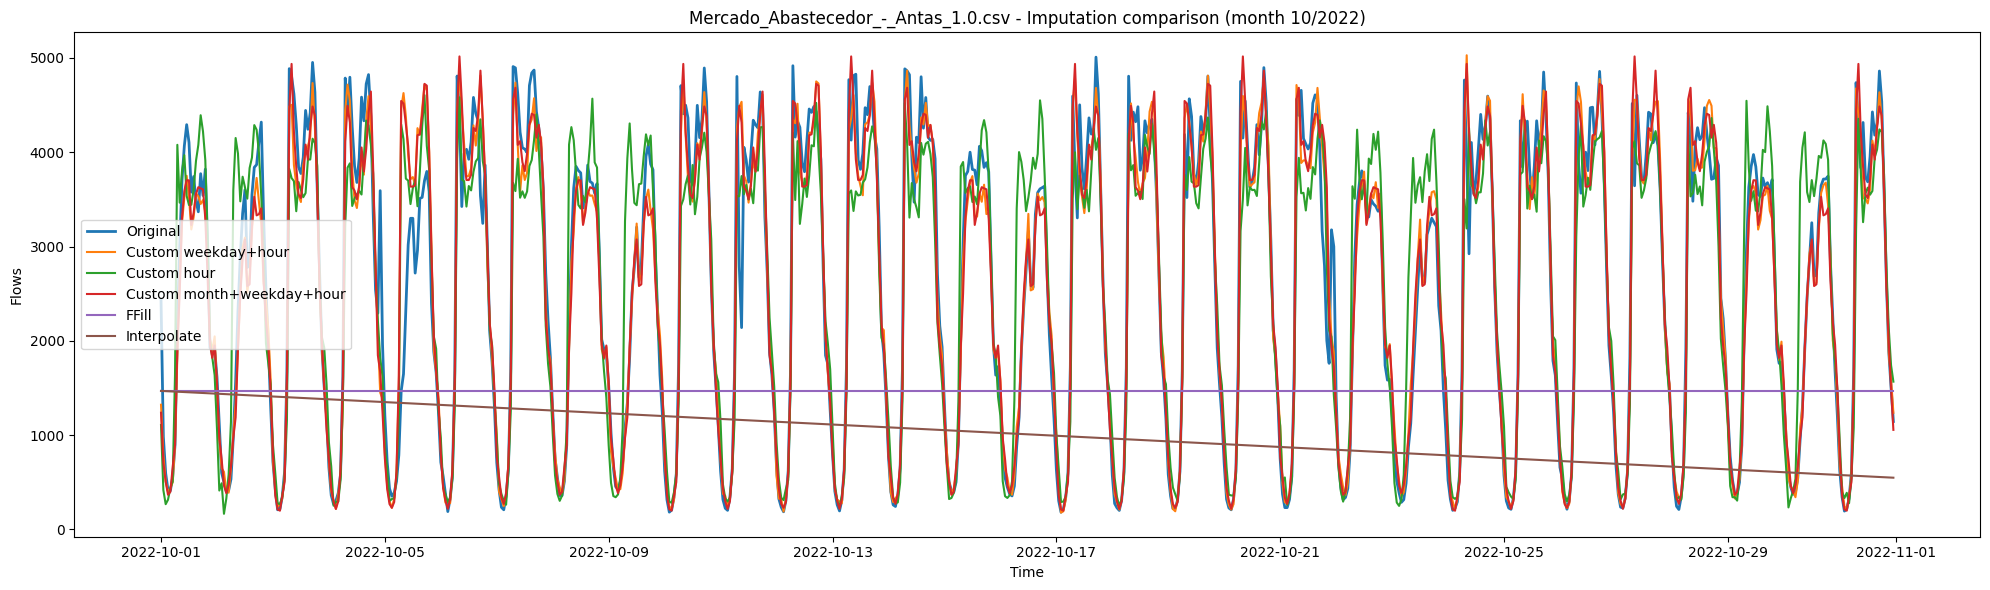


Processing Mercado_Abastecedor_-_Antas_-1.0.csv
Custom weekday+hour -> MAE: 218.24, RMSE: 361.36, SMAPE: 0.10
Custom hour -> MAE: 418.88, RMSE: 593.92, SMAPE: 0.21
Custom month+weekday+hour -> MAE: 217.13, RMSE: 361.86, SMAPE: 0.10
FFill -> MAE: 1477.36, RMSE: 1666.84, SMAPE: 0.70
Interpolate -> MAE: 1688.80, RMSE: 2011.90, SMAPE: 0.84


/tmp/ipykernel_1702801/2990542792.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


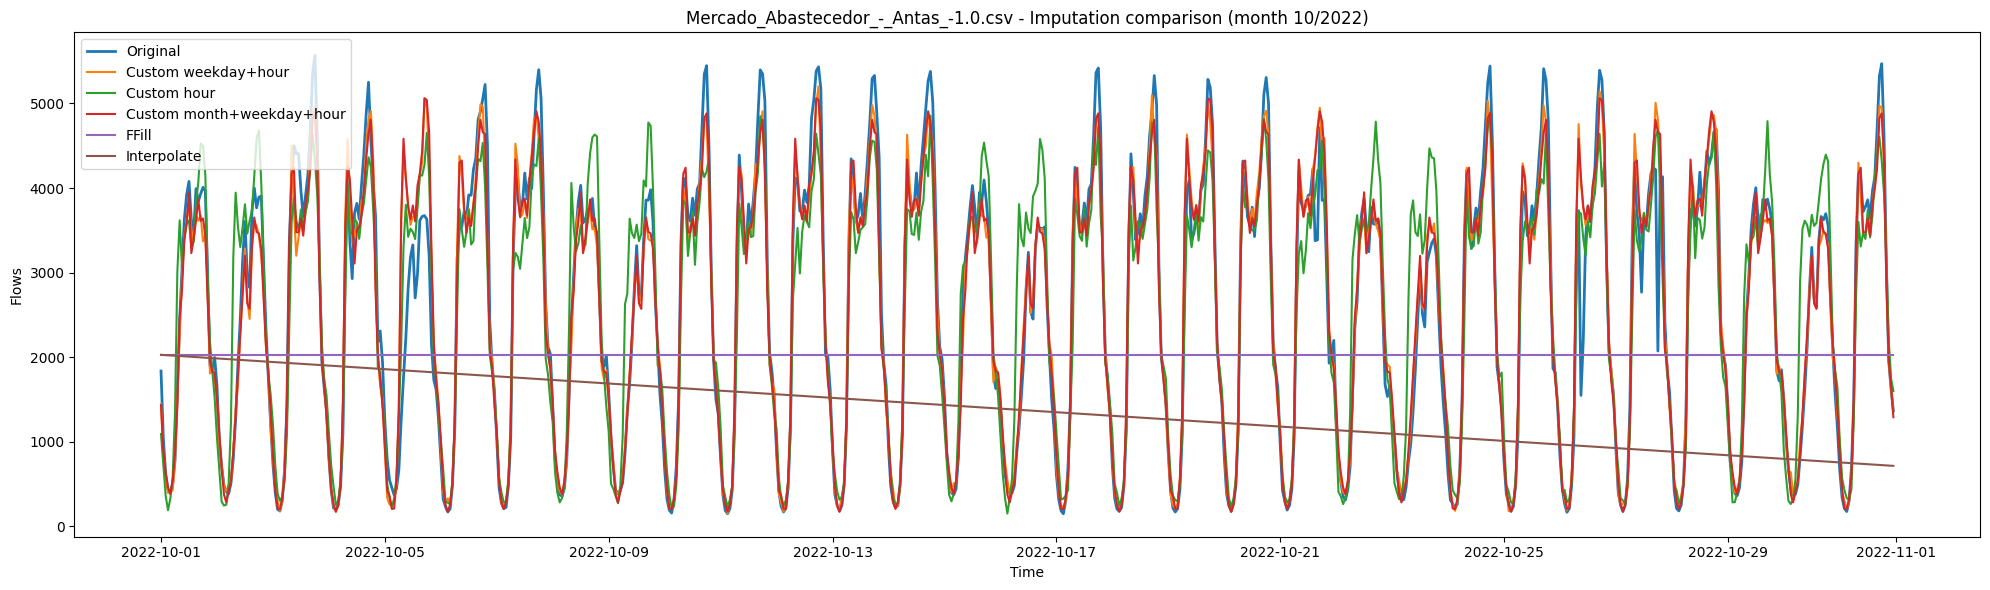


Processing A3_-_Paranhos_-1.0.csv
Custom weekday+hour -> MAE: 445.45, RMSE: 615.76, SMAPE: 0.19
Custom hour -> MAE: 628.39, RMSE: 836.87, SMAPE: 0.27
Custom month+weekday+hour -> MAE: 438.90, RMSE: 610.69, SMAPE: 0.19
FFill -> MAE: 1647.16, RMSE: 1896.68, SMAPE: 0.66
Interpolate -> MAE: 2061.78, RMSE: 2492.40, SMAPE: 0.90


/tmp/ipykernel_1702801/2990542792.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


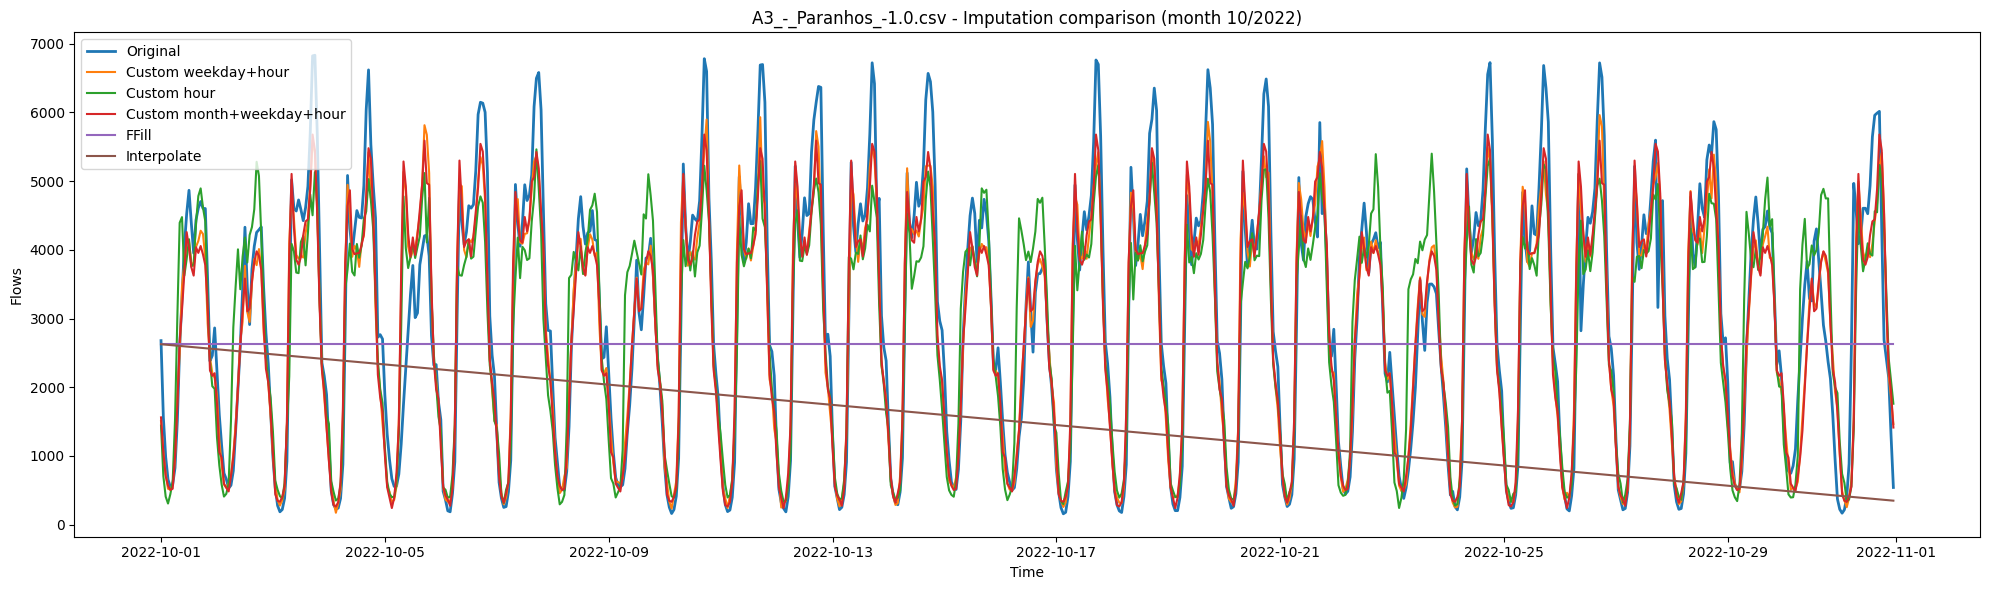


Processing A3_-_Paranhos_1.0.csv
Custom weekday+hour -> MAE: 391.68, RMSE: 620.03, SMAPE: 0.18
Custom hour -> MAE: 557.60, RMSE: 835.52, SMAPE: 0.25
Custom month+weekday+hour -> MAE: 395.89, RMSE: 629.37, SMAPE: 0.18
FFill -> MAE: 1790.52, RMSE: 2035.50, SMAPE: 0.76
Interpolate -> MAE: 2159.59, RMSE: 2616.08, SMAPE: 0.99


/tmp/ipykernel_1702801/2990542792.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


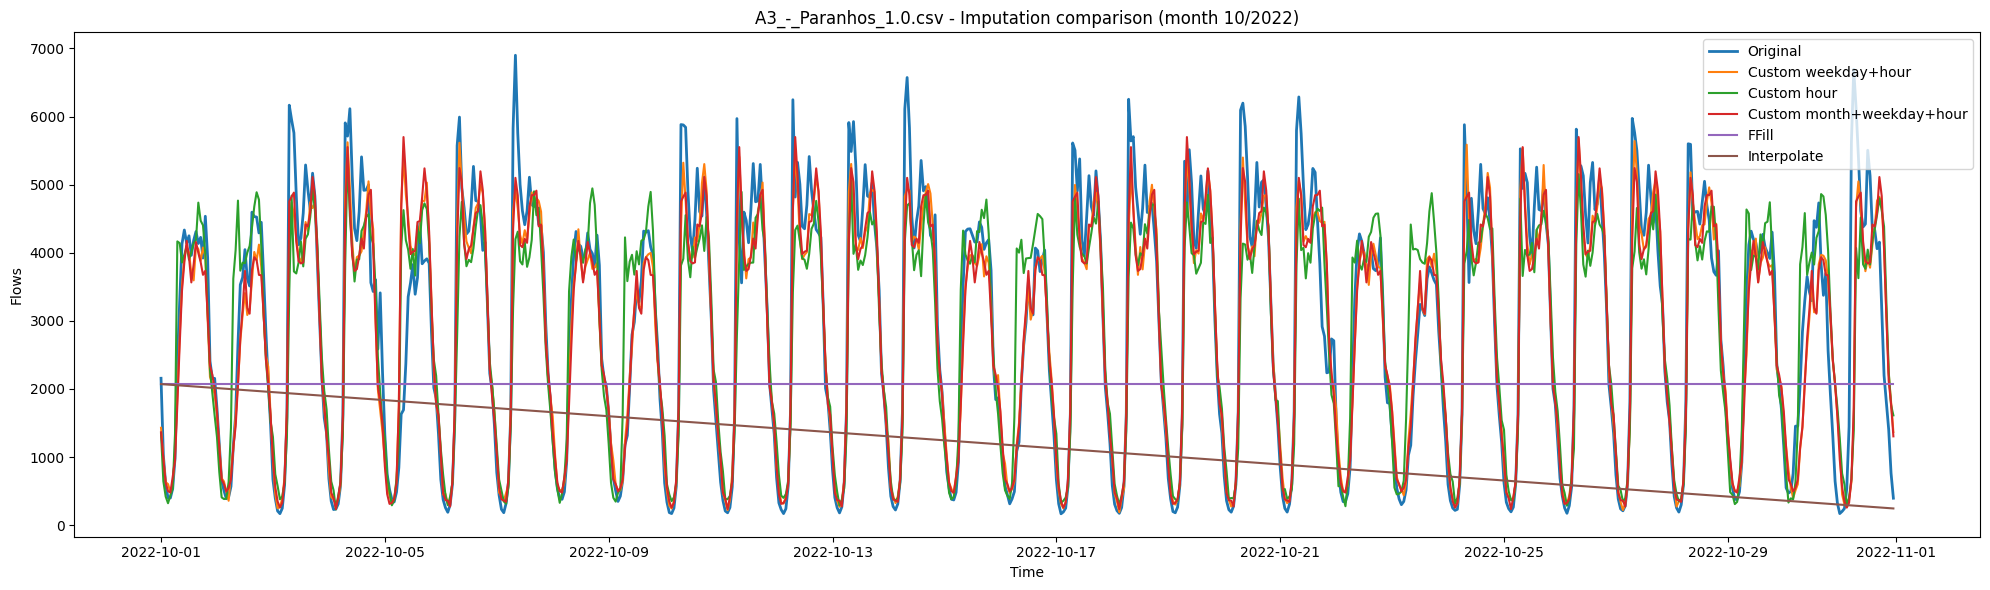

In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from input import impute
from input2 import impute2
import input3
import importlib
importlib.reload(input3)
from input3 import impute3

def impute_ffill(df):
    return df.ffill().bfill()

def impute_interpolate(df):
    return df.interpolate(method='time').bfill().ffill()

missing_month = np.random.randint(1, 13)  # random month
missing_year = np.random.choice(df.index.year.unique())

def evaluate_imputation(df_original, method_func, name, missing_month, missing_year):
    df = df_original.copy()

    mask = (df.index.month == missing_month) & (df.index.year == missing_year)
    sample_idx = df[mask & df['flows'].notna()].index

    true_values = df.loc[sample_idx, 'flows'].copy()
    df.loc[sample_idx, 'flows'] = np.nan

    # ---- impute ----
    df_imputed = method_func(df)

    pred_values = df_imputed.loc[sample_idx, 'flows']

    # ---- metrics ----
    mae = np.mean(np.abs(true_values - pred_values))
    rmse = np.sqrt(np.mean((true_values - pred_values)**2))

    denominator = (true_values.abs() + pred_values.abs() + 1e-16)
    smape = (2 * (true_values - pred_values).abs() / denominator).mean()

    print(f"{name} -> MAE: {mae:.2f}, RMSE: {rmse:.2f}, SMAPE: {smape:.2f}")

    return df, df_imputed, mae, rmse, smape

output_dir = "hourly_flows_by_detector"
for file in os.listdir(output_dir):
    if not file.endswith(".csv"):
        continue
    
    if file in ['Mercado_Abastecedor_-_Antas_1.0.csv',
        'Mercado_Abastecedor_-_Antas_-1.0.csv',
        'A3_-_Paranhos_-1.0.csv',
        'A3_-_Paranhos_1.0.csv']:
        print(f"\nProcessing {file}")

        dfori = pd.read_csv(os.path.join(output_dir, file), sep=';')
        dfori['timestamp'] = pd.to_datetime(dfori['timestamp'])
        dfori = dfori.sort_values('timestamp').set_index('timestamp')

        full_range = pd.date_range(
            start="2022-01-01 00:00:00",
            end="2024-12-31 23:00:00",
            freq="h"
        )

        df = dfori.reindex(full_range)
        df.index.name = "timestamp"
        df = df.sort_index()

        noiseFac = 0.3

        # df_custom = impute(df, noiseFac) # hour + weekday
        # df_custom2 = impute2(df, noiseFac) # hour

        df_masked, df_custom, mae_c, rmse_c, smape_c = evaluate_imputation(df, impute, "Custom weekday+hour",  missing_month, missing_year)
        _,df_custom2, mae_c2, rmse_c2, smape_c2 = evaluate_imputation(df, impute2, "Custom hour",  missing_month, missing_year)
        _,df_custom3, mae_c3, rmse_c3, smape_c2 = evaluate_imputation(df, impute3, "Custom month+weekday+hour",  missing_month, missing_year)


        _,df_ffill, mae_f, rmse_f, smape_f = evaluate_imputation(df, impute_ffill, "FFill",  missing_month, missing_year)
        _,df_interp, mae_i, rmse_i, smape_i = evaluate_imputation(df, impute_interpolate, "Interpolate",  missing_month, missing_year)

        # plt.figure(figsize=(20,6))
        # plt.plot(df_custom['timestamp'], df['flows'], label='Custom')

        # plt.plot(df.index, df['flows'], label='Original', alpha=0.6)
        # plt.title(f"{file} - Flows")
        # plt.xlabel("Time")
        # plt.ylabel("Flows")
        # plt.legend()
        # plt.tight_layout()
        # plt.show()

        mask_plot = (df.index.month == missing_month) & (df.index.year == missing_year)
        plt.figure(figsize=(20, 6))
        plt.plot(df.index[mask_plot],        df['flows'][mask_plot],          label='Original',              linewidth=2)

        plt.plot(df_custom.index[mask_plot], df_custom['flows'][mask_plot],   label='Custom weekday+hour')
        plt.plot(df_custom2.index[mask_plot],df_custom2['flows'][mask_plot],  label='Custom hour')
        plt.plot(df_custom3.index[mask_plot],df_custom3['flows'][mask_plot],  label='Custom month+weekday+hour')
        plt.plot(df_ffill.index[mask_plot],  df_ffill['flows'][mask_plot],    label='FFill')
        plt.plot(df_interp.index[mask_plot], df_interp['flows'][mask_plot],   label='Interpolate')
        plt.title(f"{file} - Imputation comparison (month {missing_month}/{missing_year})")
        plt.xlabel("Time")
        plt.ylabel("Flows")
        plt.legend()
        plt.tight_layout()
        plt.show()

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from input import impute
from input2 import impute2
import input3
import importlib
importlib.reload(input3)
from input3 import impute3

def impute_ffill(df):
    return df.ffill().bfill()

def impute_interpolate(df):
    return df.interpolate(method='time').bfill().ffill()

def evaluate_imputation(df_original, method_func, name, missing_month, missing_year):
    df = df_original.copy()

    mask = (df.index.month == missing_month) & (df.index.year == missing_year)
    sample_idx = df[mask & df['flows'].notna()].index

    true_values = df.loc[sample_idx, 'flows'].copy()
    df.loc[sample_idx, 'flows'] = np.nan

    # ---- impute ----
    df_imputed = method_func(df)

    pred_values = df_imputed.loc[sample_idx, 'flows']

    # ---- metrics ----
    mae = np.mean(np.abs(true_values - pred_values))
    rmse = np.sqrt(np.mean((true_values - pred_values)**2))

    denominator = (true_values.abs() + pred_values.abs() + 1e-16)
    smape = (2 * (true_values - pred_values).abs() / denominator).mean()

    print(f"{name} -> MAE: {mae:.2f}, RMSE: {rmse:.2f}, SMAPE: {smape:.2f}")

    return df, df_imputed, mae, rmse, smape

In [ ]:
import os
import pandas as pd
import numpy as np

output_dir = "hourly_flows_by_detector"

missing_month = 4
missing_year = 2023

results_list = []  


for file in os.listdir(output_dir):
    if not file.endswith(".csv"):
        continue
    
    dfori = pd.read_csv(os.path.join(output_dir, file), sep=';')
    dfori['timestamp'] = pd.to_datetime(dfori['timestamp'])
    dfori = dfori.sort_values('timestamp').set_index('timestamp')

    full_range = pd.date_range(
        start="2022-01-01 00:00:00",
        end="2024-12-31 23:00:00",
        freq="h"
    )

    df = dfori.reindex(full_range)
    df.index.name = "timestamp"
    df = df.sort_index()

    noiseFac = 0.3

    methods_to_test = [
        (impute, "Custom WD+H"),
        (impute2, "Custom H"),
        (impute3, "Custom M+WD+H"),
        (impute_ffill, "FFill"),
        (impute_interpolate, "Interpolate")
    ]

    for method_func, method_name in methods_to_test:
        _, _, mae, rmse, smape = evaluate_imputation(df, method_func, method_name, missing_month, missing_year)
        

        results_list.append({
            'Detector': file.replace('.csv', ''),
            'Method': method_name,
            'MAE': mae,
            'RMSE': rmse,
            'SMAPE': smape
        })


df_results = pd.DataFrame(results_list)

print("\n--- Detailed Metrics per Detector ---")
detailed_table = df_results.sort_values(['Detector', 'Method'])
print(detailed_table.to_string(index=False))

print("\n--- Average Performance per Method ---")
summary_table = df_results.groupby('Method')[['MAE', 'RMSE', 'SMAPE']].mean().sort_values('MAE')
print(summary_table)


Custom WD+H -> MAE: 398.89, RMSE: 657.98, SMAPE: 0.15
Custom H -> MAE: 563.07, RMSE: 846.46, SMAPE: 0.23
Custom M+WD+H -> MAE: 411.77, RMSE: 674.05, SMAPE: 0.15
FFill -> MAE: 1702.64, RMSE: 1939.33, SMAPE: 0.72
Interpolate -> MAE: 1844.99, RMSE: 2157.85, SMAPE: 0.79


/tmp/ipykernel_2855426/1936025010.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


Custom WD+H -> MAE: 256.66, RMSE: 394.13, SMAPE: 0.14
Custom H -> MAE: 337.28, RMSE: 515.37, SMAPE: 0.20
Custom M+WD+H -> MAE: 219.79, RMSE: 342.42, SMAPE: 0.13
FFill -> MAE: 1126.59, RMSE: 1266.70, SMAPE: 0.63
Interpolate -> MAE: 1231.99, RMSE: 1414.21, SMAPE: 0.70


/tmp/ipykernel_2855426/1936025010.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


Custom WD+H -> MAE: 318.60, RMSE: 441.55, SMAPE: 0.13
Custom H -> MAE: 435.19, RMSE: 657.20, SMAPE: 0.20
Custom M+WD+H -> MAE: 300.74, RMSE: 412.51, SMAPE: 0.12
FFill -> MAE: 1634.86, RMSE: 1847.91, SMAPE: 0.74
Interpolate -> MAE: 1765.05, RMSE: 2037.62, SMAPE: 0.82


...

/tmp/ipykernel_2855426/1936025010.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


Custom WD+H -> MAE: 311.31, RMSE: 497.96, SMAPE: 0.12
Custom H -> MAE: 529.99, RMSE: 815.82, SMAPE: 0.21
Custom M+WD+H -> MAE: 306.40, RMSE: 509.15, SMAPE: 0.12
FFill -> MAE: 1797.02, RMSE: 2038.28, SMAPE: 0.72
Interpolate -> MAE: 1960.29, RMSE: 2297.21, SMAPE: 0.80


/tmp/ipykernel_2855426/1936025010.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


Custom WD+H -> MAE: 509.18, RMSE: 731.67, SMAPE: 0.23
Custom H -> MAE: 650.59, RMSE: 933.82, SMAPE: 0.30
Custom M+WD+H -> MAE: 487.33, RMSE: 719.92, SMAPE: 0.20
FFill -> MAE: 1869.80, RMSE: 2172.11, SMAPE: 0.78
Interpolate -> MAE: 2028.72, RMSE: 2414.60, SMAPE: 0.87

--- Detailed Metrics per Detector ---
                              Detector        Method         MAE        RMSE    SMAPE
                    A3_-_Paranhos_-1.0      Custom H  685.859523  908.763821 0.307541
                    A3_-_Paranhos_-1.0 Custom M+WD+H  559.304286  756.784709 0.227390
                    A3_-_Paranhos_-1.0   Custom WD+H  552.877663  740.434449 0.245571
                    A3_-_Paranhos_-1.0         FFill 1638.690278 1899.606337 0.633604
                    A3_-_Paranhos_-1.0   Interpolate 1807.336938 2117.192413 0.722874
                     A3_-_Paranhos_1.0      Custom H  650.593256  933.818299 0.296809
                     A3_-_Paranhos_1.0 Custom M+WD+H  487.333920  719.919253 0.200314
      

/tmp/ipykernel_2855426/1936025010.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


In [6]:
import os
import pandas as pd
import numpy as np

output_dir = "hourly_flows_by_detector"

missing_month = 6
missing_year = 2022

results_list = []  


for file in os.listdir(output_dir):
    if not file.endswith(".csv"):
        continue
    
    dfori = pd.read_csv(os.path.join(output_dir, file), sep=';')
    dfori['timestamp'] = pd.to_datetime(dfori['timestamp'])
    dfori = dfori.sort_values('timestamp').set_index('timestamp')

    full_range = pd.date_range(
        start="2022-01-01 00:00:00",
        end="2024-12-31 23:00:00",
        freq="h"
    )

    df = dfori.reindex(full_range)
    df.index.name = "timestamp"
    df = df.sort_index()

    noiseFac = 0.3

    methods_to_test = [
        (impute, "Custom WD+H"),
        (impute2, "Custom H"),
        (impute3, "Custom M+WD+H"),
        (impute_ffill, "FFill"),
        (impute_interpolate, "Interpolate")
    ]

    for method_func, method_name in methods_to_test:
        _, _, mae, rmse, smape = evaluate_imputation(df, method_func, method_name, missing_month, missing_year)
        

        results_list.append({
            'Detector': file.replace('.csv', ''),
            'Method': method_name,
            'MAE': mae,
            'RMSE': rmse,
            'SMAPE': smape
        })


df_results = pd.DataFrame(results_list)

print("\n--- Detailed Metrics per Detector ---")
detailed_table = df_results.sort_values(['Detector', 'Method'])
print(detailed_table.to_string(index=False))

print("\n--- Average Performance per Method ---")
summary_table = df_results.groupby('Method')[['MAE', 'RMSE', 'SMAPE']].mean().sort_values('MAE')
print(summary_table)


Custom WD+H -> MAE: 322.41, RMSE: 539.06, SMAPE: 0.15
Custom H -> MAE: 513.69, RMSE: 754.66, SMAPE: 0.21
Custom M+WD+H -> MAE: 318.08, RMSE: 535.44, SMAPE: 0.15
FFill -> MAE: 1891.62, RMSE: 2252.46, SMAPE: 0.84
Interpolate -> MAE: 1923.87, RMSE: 2295.86, SMAPE: 0.85


/tmp/ipykernel_2855426/1936025010.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


Custom WD+H -> MAE: 374.42, RMSE: 493.07, SMAPE: 0.19
Custom H -> MAE: 485.35, RMSE: 645.95, SMAPE: 0.24
Custom M+WD+H -> MAE: 379.22, RMSE: 501.40, SMAPE: 0.20
FFill -> MAE: 1472.46, RMSE: 1763.23, SMAPE: 0.77
Interpolate -> MAE: 1417.41, RMSE: 1688.11, SMAPE: 0.74


/tmp/ipykernel_2855426/1936025010.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


Custom WD+H -> MAE: 321.35, RMSE: 443.98, SMAPE: 0.19
Custom H -> MAE: 462.16, RMSE: 648.79, SMAPE: 0.23
Custom M+WD+H -> MAE: 317.56, RMSE: 443.01, SMAPE: 0.18
FFill -> MAE: 1731.29, RMSE: 2081.68, SMAPE: 0.82
Interpolate -> MAE: 1633.74, RMSE: 1951.65, SMAPE: 0.76


...

/tmp/ipykernel_2855426/1936025010.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


Custom WD+H -> MAE: 318.47, RMSE: 575.30, SMAPE: 0.14
Custom H -> MAE: 518.92, RMSE: 787.21, SMAPE: 0.21
Custom M+WD+H -> MAE: 325.05, RMSE: 581.80, SMAPE: 0.14
FFill -> MAE: 1979.57, RMSE: 2364.17, SMAPE: 0.83
Interpolate -> MAE: 2096.26, RMSE: 2525.99, SMAPE: 0.89


/tmp/ipykernel_2855426/1936025010.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


Custom WD+H -> MAE: 298.30, RMSE: 442.63, SMAPE: 0.14
Custom H -> MAE: 447.58, RMSE: 644.37, SMAPE: 0.19
Custom M+WD+H -> MAE: 289.89, RMSE: 435.51, SMAPE: 0.14
FFill -> MAE: 1716.50, RMSE: 2040.24, SMAPE: 0.74
Interpolate -> MAE: 1675.12, RMSE: 1981.76, SMAPE: 0.72

--- Detailed Metrics per Detector ---
                              Detector        Method         MAE        RMSE    SMAPE
                    A3_-_Paranhos_-1.0      Custom H  460.355126  666.180790 0.198617
                    A3_-_Paranhos_-1.0 Custom M+WD+H  292.325205  437.033418 0.139746
                    A3_-_Paranhos_-1.0   Custom WD+H  290.379591  437.038466 0.138197
                    A3_-_Paranhos_-1.0         FFill 1716.498611 2040.244414 0.744015
                    A3_-_Paranhos_-1.0   Interpolate 1675.121978 1981.756322 0.721617
                     A3_-_Paranhos_1.0      Custom H  447.578429  644.365673 0.193906
                     A3_-_Paranhos_1.0 Custom M+WD+H  289.892049  435.508345 0.135539
      

/tmp/ipykernel_2855426/1936025010.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


In [7]:
summary_table.to_latex("imputation_summaryjun22.tex")